# Optimización de Portafolios — Deep Learning: LSTM

## Parte 3: Capa de Deep Learning

**Jacqueline Espinosa** — Lic. en Actuaría, FCFM UANL
Octubre 2026

---

En la Parte 2 usé Random Forest y XGBoost para predecir rendimientos. Los dos funcionan con features calculados en un solo punto en el tiempo: reciben los indicadores técnicos del día que quiero predecir y dan una respuesta.

El problema es que pierden contexto temporal. Un RSI de 65 no significa lo mismo si viene subiendo desde 30 (momentum alcista) que si viene bajando desde 90 (señal de debilitamiento). RF y XGB ven el número pero no la trayectoria.

Aquí uso LSTM (Long Short-Term Memory), un tipo de red neuronal diseñada para series de tiempo. En vez de recibir los features de un solo día, recibe la secuencia de los últimos 60 días hábiles y aprende patrones temporales: cómo evolucionaron los indicadores y qué pasó después.

**Plan:**

| Parte | Qué hace | |
|-------|----------|-|
| 1 — Markowitz | Optimización clásica media-varianza | listo |
| 2 — ML | XGBoost / Random Forest | listo |
| 3 — DL | LSTM para series de tiempo | (este notebook) |
| 4 — Backtesting | Comparar todas las estrategias | pendiente |

---
## Contexto teórico

### Redes neuronales (resumen rápido)

Una red neuronal transforma datos a través de capas de neuronas. Cada neurona toma sus entradas, las multiplica por pesos, suma todo, y aplica una función de activación no lineal. El entrenamiento ajusta los pesos para minimizar el error de predicción (la "loss function").

La ventaja de las redes neuronales es que pueden aprender relaciones no lineales complejas. Con suficientes neuronas y capas, teóricamente pueden aproximar cualquier función — el teorema de aproximación universal.

### Redes recurrentes (RNN) y el problema del gradiente

Para datos secuenciales (texto, audio, series de tiempo), se inventaron las RNN: redes que procesan un paso de la secuencia a la vez y mantienen un "estado oculto" que funciona como memoria. En cada paso, la red recibe la entrada actual + el estado del paso anterior y produce un nuevo estado.

El problema es que al entrenar con secuencias largas, los gradientes (las señales que ajustan los pesos durante backpropagation) se multiplican muchas veces y terminan haciéndose cero (vanishing gradient) o explotando. En la práctica una RNN básica solo recuerda los últimos 10-20 pasos.

### LSTM: memoria selectiva

Las LSTM (Hochreiter & Schmidhuber, 1997) resuelven esto con un mecanismo de tres compuertas que decide qué información recordar y qué olvidar:

- **Forget gate** — decide qué parte del estado anterior descartar. "Esa tendencia alcista de hace 2 meses ya no es relevante."
- **Input gate** — decide qué información nueva incorporar. "El RSI acaba de cruzar 70, eso es importante."
- **Output gate** — decide qué parte del estado usar para la predicción actual.

Las compuertas se implementan con funciones sigmoide (valores entre 0 y 1) que actúan como filtros: 0 = bloquear completamente, 1 = dejar pasar todo. Los pesos de estas compuertas se aprenden durante el entrenamiento, así que el modelo decide automáticamente qué recordar y qué olvidar.

Gracias a este mecanismo las LSTM pueden capturar dependencias de hasta cientos de pasos, mucho más que una RNN básica.

### LSTM para series financieras

¿Por qué LSTM tiene sentido para predecir rendimientos?

1. **Patrones temporales** — Los mercados tienen patrones que dependen de la historia reciente. Un breakout técnico (el precio rompe una resistencia) importa más si viene después de una consolidación larga. LSTM puede capturar ese tipo de contexto que los features puntuales no expresan.

2. **Volatility clustering** — La volatilidad alta tiende a seguir a volatilidad alta. LSTM puede aprender la dinámica: si las últimas semanas fueron volátiles, probablemente las próximas también lo serán.

3. **Cambios de régimen** — Los mercados cambian de régimen (alcista, bajista, lateral). Una secuencia de features captura mejor en qué régimen estamos que un snapshot de un solo día.

Lo que hago en este notebook:
- Tomo los mismos 12 features técnicos de la Parte 2
- Para cada día, armo una secuencia con los features de los últimos 60 días hábiles (~3 meses)
- La LSTM procesa esa secuencia y predice el rendimiento a 21 días
- Esas predicciones alimentan el mismo optimizador de Markowitz

---
## 1. Librerías

In [7]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'  # Suprime warnings de TF sobre GPU

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from scipy.optimize import minimize
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, r2_score
import warnings
warnings.filterwarnings('ignore')

# TensorFlow / Keras
try:
    import tensorflow as tf
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.layers import LSTM, Dense, Dropout
    from tensorflow.keras.callbacks import EarlyStopping
    tf.random.set_seed(42)
    print(f"TensorFlow {tf.__version__} listo")
except ImportError:
    raise ImportError(
        "Falta TensorFlow. Corre en la terminal:\n"
        "  pip install tensorflow\n"
        "O con conda:\n"
        "  conda install -c conda-forge tensorflow"
    )

np.random.seed(42)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 7)
plt.rcParams['font.size'] = 12

TensorFlow 2.22.0-rc0 listo


## 2. Datos

Mismas 10 acciones y periodo que las partes anteriores.

In [8]:
TICKERS = ['AAPL', 'MSFT', 'JPM', 'JNJ', 'XOM', 'KO', 'AMZN', 'NVDA', 'CAT', 'PG']
BENCHMARK = 'SPY'
START = '2020-01-01'
END   = '2024-12-31'
RISK_FREE_RATE = 0.05
TRADING_DAYS = 252
HORIZON = 21    # dias habiles del target
SEQ_LEN = 60    # dias de historia que ve la LSTM

all_tickers = TICKERS + [BENCHMARK]
data = yf.download(all_tickers, start=START, end=END, auto_adjust=True)

if isinstance(data.columns, pd.MultiIndex):
    prices = data['Close'][all_tickers]
else:
    prices = data[all_tickers]

failed = prices.columns[prices.isna().all()]
if len(failed) > 0:
    print(f"No se pudieron descargar: {list(failed)}")
    print("Vuelve a correr esta celda o reinicia el kernel.")

prices = prices.dropna()
print(f"Periodo: {prices.index[0].date()} a {prices.index[-1].date()}")
print(f"Dias de trading: {len(prices)}")

[*********************100%***********************]  11 of 11 completed

Periodo: 2020-01-02 a 2024-12-30
Dias de trading: 1257


## 3. Feature Engineering

Mismos 12 features técnicos que la Parte 2. La diferencia es cómo los usa el modelo: RF y XGB veían una fila a la vez; LSTM va a ver 60 filas seguidas como una secuencia.

In [9]:
def compute_features(close):
    """Calcula features tecnicos para una serie de precios."""
    df = pd.DataFrame(index=close.index)
    ret_1d = close.pct_change()

    # --- Momentum ---
    df['ret_1d']  = ret_1d
    df['ret_5d']  = close.pct_change(5)
    df['ret_10d'] = close.pct_change(10)
    df['ret_21d'] = close.pct_change(21)

    # --- Promedios moviles vs precio ---
    df['sma10_ratio'] = close / close.rolling(10).mean()
    df['sma20_ratio'] = close / close.rolling(20).mean()
    df['sma50_ratio'] = close / close.rolling(50).mean()

    # --- RSI ---
    delta = close.diff()
    gain  = delta.clip(lower=0).rolling(14).mean()
    loss  = (-delta.clip(upper=0)).rolling(14).mean()
    rs = gain / loss
    df['rsi_14'] = 100 - (100 / (1 + rs))

    # --- MACD normalizado ---
    ema12 = close.ewm(span=12, adjust=False).mean()
    ema26 = close.ewm(span=26, adjust=False).mean()
    macd_line   = ema12 - ema26
    signal_line = macd_line.ewm(span=9, adjust=False).mean()
    df['macd_diff'] = (macd_line - signal_line) / close

    # --- Bollinger %B ---
    sma20 = close.rolling(20).mean()
    std20 = close.rolling(20).std()
    upper = sma20 + 2 * std20
    lower = sma20 - 2 * std20
    df['bb_pct'] = (close - lower) / (upper - lower)

    # --- Volatilidad ---
    df['vol_10d'] = ret_1d.rolling(10).std()
    df['vol_21d'] = ret_1d.rolling(21).std()

    return df

FEATURE_COLS = [
    'ret_1d', 'ret_5d', 'ret_10d', 'ret_21d',
    'sma10_ratio', 'sma20_ratio', 'sma50_ratio',
    'rsi_14', 'macd_diff', 'bb_pct',
    'vol_10d', 'vol_21d'
]

In [10]:
stock_data = {}

for ticker in TICKERS:
    feats = compute_features(prices[ticker])
    feats['target'] = prices[ticker].shift(-HORIZON) / prices[ticker] - 1
    feats = feats.dropna()
    stock_data[ticker] = feats

print(f"Features: {len(FEATURE_COLS)}")
print(f"Observaciones por accion: ~{len(stock_data['AAPL'])}")

Features: 12
Observaciones por accion: ~1187


## 4. Preparación de secuencias

Aquí está la diferencia clave con la Parte 2. En vez de alimentar una fila de 12 features al modelo, le doy una ventana deslizante de 60 días: una matriz de 60 filas x 12 columnas.

Para el día *t*, la entrada es la matriz de features de los días *t-60* a *t-1*. El target sigue siendo el rendimiento de *t* a *t+21*.

Antes de crear las secuencias, normalizo los features con StandardScaler (media 0, desviación estándar 1). Las redes neuronales son muy sensibles a la escala de los datos: un feature que oscila entre 0 y 100 (como el RSI) dominaría sobre uno que va de -0.03 a 0.03 (como ret_1d). El scaler se ajusta SOLO con datos de entrenamiento para no filtrar información del futuro.

Las secuencias del test set sí pueden usar datos de finales de 2023 como parte de su ventana de 60 días — en la práctica tendríamos esos datos disponibles al momento de predecir en enero 2024.

In [11]:
SPLIT_DATE = '2024-01-01'

seq_data = {}

for ticker in TICKERS:
    df = stock_data[ticker]
    dates = df.index
    X_all = df[FEATURE_COLS].values
    y_all = df['target'].values

    # Ajustar scaler solo con entrenamiento
    train_mask = dates < pd.Timestamp(SPLIT_DATE)
    scaler = StandardScaler()
    scaler.fit(X_all[train_mask])
    X_scaled = scaler.transform(X_all)

    # Crear secuencias con ventana deslizante
    X_seq, y_seq, d_seq = [], [], []
    for i in range(SEQ_LEN, len(X_scaled)):
        X_seq.append(X_scaled[i - SEQ_LEN : i])   # shape: (60, 12)
        y_seq.append(y_all[i])
        d_seq.append(dates[i])

    X_seq = np.array(X_seq)
    y_seq = np.array(y_seq)
    d_seq = np.array(d_seq)

    # Separar por fecha del target
    split_mask = np.array([d < pd.Timestamp(SPLIT_DATE) for d in d_seq])
    seq_data[ticker] = {
        'X_train': X_seq[split_mask],
        'y_train': y_seq[split_mask],
        'X_test':  X_seq[~split_mask],
        'y_test':  y_seq[~split_mask],
        'd_test':  d_seq[~split_mask],
        'scaler':  scaler,
    }

# Verificar dimensiones
tk0 = TICKERS[0]
print(f"Forma de cada secuencia: {seq_data[tk0]['X_train'].shape[1:]}  (60 dias x 12 features)")
print()
print(f"{'Ticker':>8s}  {'Train':>6s}  {'Test':>5s}")
print("-" * 26)
for tk in TICKERS:
    nt = len(seq_data[tk]['X_train'])
    ns = len(seq_data[tk]['X_test'])
    print(f"{tk:>8s}  {nt:>6d}  {ns:>5d}")

Forma de cada secuencia: (60, 12)  (60 dias x 12 features)

  Ticker   Train   Test
--------------------------
    AAPL     897    230
    MSFT     897    230
     JPM     897    230
     JNJ     897    230
     XOM     897    230
      KO     897    230
    AMZN     897    230
    NVDA     897    230
     CAT     897    230
      PG     897    230


Se pierden las primeras 60 observaciones porque LSTM necesita una ventana completa de 60 días para hacer la primera predicción. Es el precio de darle contexto temporal al modelo.

## 5. Arquitectura del modelo

Uso dos capas LSTM apiladas con Dropout:

- **LSTM(64, return_sequences=True)** — primera capa con 64 unidades. Procesa la secuencia paso a paso y pasa su secuencia de estados ocultos a la siguiente capa. `return_sequences=True` porque la segunda LSTM necesita recibir toda la secuencia, no solo el último estado.
- **Dropout(0.2)** — apaga aleatoriamente el 20% de las neuronas en cada paso de entrenamiento. Esto fuerza a la red a no depender de neuronas individuales y reduce overfitting.
- **LSTM(32)** — segunda capa con 32 unidades. Extrae patrones más abstractos sobre lo que aprendió la primera. Solo devuelve el último estado oculto (el resumen de toda la secuencia).
- **Dropout(0.2)** — otra capa de regularización.
- **Dense(1)** — una neurona de salida que produce el rendimiento predicho.

Optimizador: Adam (estándar en deep learning, adapta la tasa de aprendizaje por parámetro).
Loss: MSE (error cuadrático medio).

In [12]:
def build_lstm_model(seq_len, n_features):
    model = Sequential([
        LSTM(64, return_sequences=True, input_shape=(seq_len, n_features)),
        Dropout(0.2),
        LSTM(32),
        Dropout(0.2),
        Dense(1)
    ])
    model.compile(optimizer='adam', loss='mse')
    return model

# Ver la arquitectura
sample_model = build_lstm_model(SEQ_LEN, len(FEATURE_COLS))
sample_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 64)         │        19,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,161 (125.63 KB)

 Trainable params: 32,161 (125.63 KB)

 Non-trainable params: 0 (0.00 B)

El modelo tiene alrededor de 29,000 parámetros entrenables. Es modesto para deep learning (GPT tiene miles de millones), pero es proporcional a la cantidad de datos que tenemos. Con ~900 secuencias de entrenamiento por acción, un modelo más grande se memorizaría el ruido.

## 6. Entrenamiento

Entreno un modelo por acción (10 LSTM). Cada modelo corre hasta 50 epochs con early stopping: si el error de validación no mejora en 10 epochs consecutivos, para y restaura los mejores pesos. El 15% final del set de entrenamiento se usa como validación (al ser temporal, es la porción más cercana al test set).

El entrenamiento puede tomar 5-15 minutos dependiendo de tu computadora (las LSTM son más pesadas que RF/XGB). Si tienes GPU con CUDA, TensorFlow la usa automáticamente y va más rápido.

In [13]:
lstm_models    = {}
lstm_histories = {}

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=0
)

for ticker in TICKERS:
    print(f"Entrenando {ticker}...", end=" ", flush=True)

    model = build_lstm_model(SEQ_LEN, len(FEATURE_COLS))

    history = model.fit(
        seq_data[ticker]['X_train'],
        seq_data[ticker]['y_train'],
        epochs=50,
        batch_size=32,
        validation_split=0.15,
        callbacks=[early_stop],
        verbose=0
    )

    lstm_models[ticker] = model
    lstm_histories[ticker] = history.history
    n_ep = len(history.history['loss'])
    print(f"listo ({n_ep} epochs)")

print("\nTodos los modelos entrenados.")

Entrenando AAPL... listo (11 epochs)
Entrenando MSFT... listo (43 epochs)
Entrenando JPM... listo (11 epochs)
Entrenando JNJ... listo (12 epochs)
Entrenando XOM... listo (11 epochs)
Entrenando KO... listo (19 epochs)
Entrenando AMZN... listo (12 epochs)
Entrenando NVDA... listo (11 epochs)
Entrenando CAT... listo (11 epochs)
Entrenando PG... listo (14 epochs)

Todos los modelos entrenados.


### Curvas de entrenamiento

El loss (MSE) por epoch me dice si el modelo aprendió bien o hay overfitting. Si el loss de entrenamiento baja pero el de validación sube, está memorizando el ruido en vez de aprender la señal.

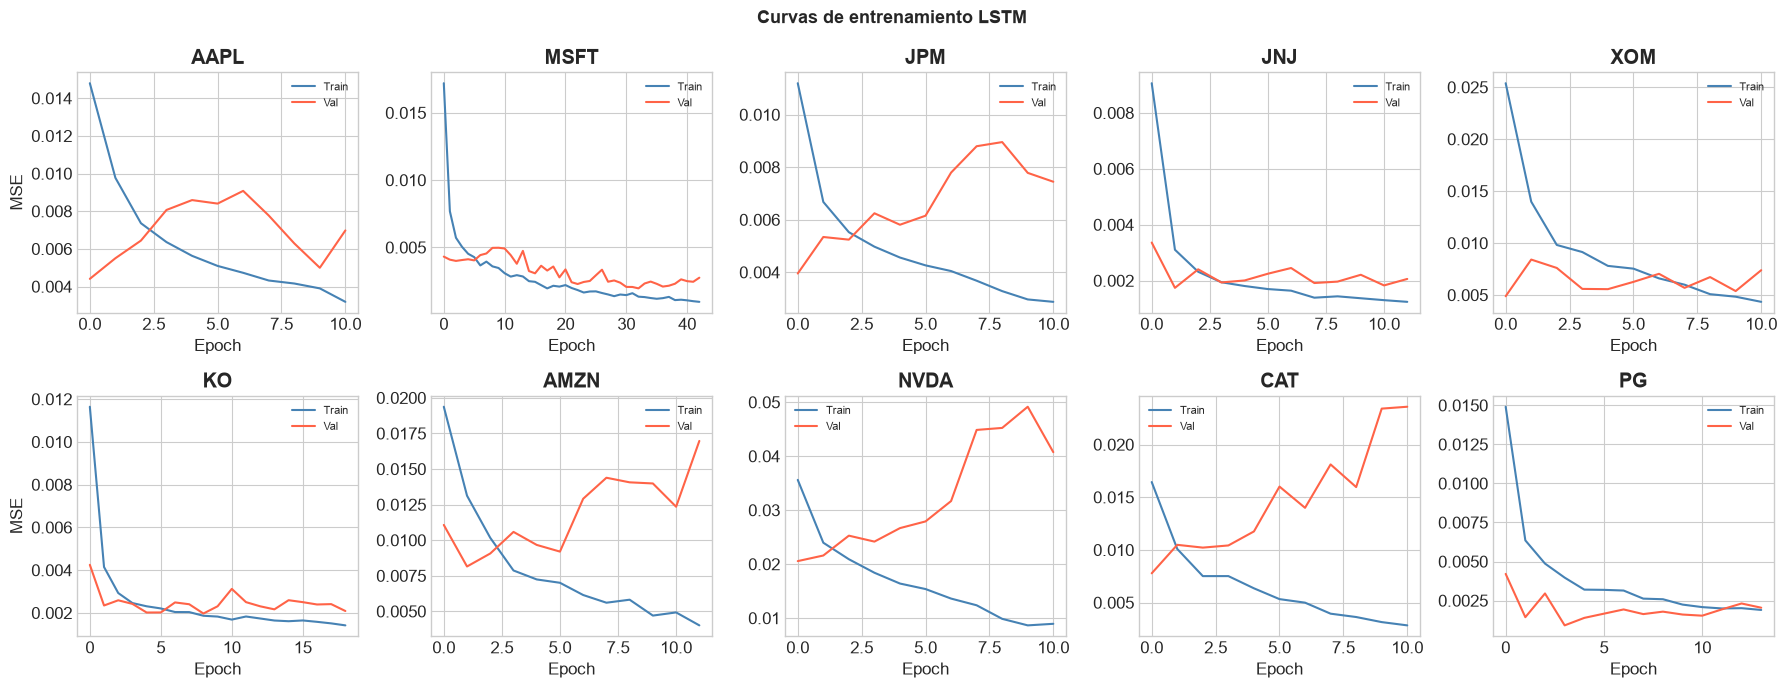

In [14]:
fig, axes = plt.subplots(2, 5, figsize=(18, 7), sharex=False)

for ax, ticker in zip(axes.flat, TICKERS):
    h = lstm_histories[ticker]
    ax.plot(h['loss'], label='Train', color='steelblue')
    ax.plot(h['val_loss'], label='Val', color='tomato')
    ax.set_title(ticker, fontweight='bold')
    ax.set_xlabel('Epoch')
    if ax in [axes[0, 0], axes[1, 0]]:
        ax.set_ylabel('MSE')
    ax.legend(fontsize=8)

plt.suptitle('Curvas de entrenamiento LSTM',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

Lo ideal es que ambas curvas bajen juntas y se estabilicen. Si la curva de validación se separa mucho de la de entrenamiento, el early stopping la frena antes de que el overfitting empeore. La cantidad de epochs donde paró cada modelo está arriba en los mensajes de entrenamiento.

## 7. Evaluación

Mismas métricas que la Parte 2 para poder comparar: R², MAE y accuracy direccional.

In [15]:
eval_rows = []

for ticker in TICKERS:
    y_te   = seq_data[ticker]['y_test']
    p_lstm = lstm_models[ticker].predict(
        seq_data[ticker]['X_test'], verbose=0
    ).flatten()

    eval_rows.append({
        'Ticker':    ticker,
        'R2_LSTM':   r2_score(y_te, p_lstm),
        'MAE_LSTM':  mean_absolute_error(y_te, p_lstm),
        'Dir_LSTM':  np.mean(np.sign(p_lstm) == np.sign(y_te)) * 100,
    })

eval_df = pd.DataFrame(eval_rows).set_index('Ticker')

print("=== LSTM ===")
view = eval_df.copy()
view.columns = ['R\u00b2', 'MAE', 'Dir Acc (%)']
print(view.round(4).to_string())
print(f"\nPromedio R\u00b2:       {eval_df['R2_LSTM'].mean():.4f}")
print(f"Promedio Dir Acc:  {eval_df['Dir_LSTM'].mean():.1f}%")

=== LSTM ===
            R²     MAE  Dir Acc (%)
Ticker                             
AAPL   -0.4468  0.0636      51.3043
MSFT   -0.6530  0.0530      61.3043
JPM    -0.6503  0.0537      56.9565
JNJ    -0.0976  0.0380      49.1304
XOM    -0.7336  0.0591      54.3478
KO      0.0310  0.0336      71.3043
AMZN   -0.7642  0.0684      57.3913
NVDA   -0.4507  0.1562      54.7826
CAT    -0.4816  0.0687      46.0870
PG     -0.1062  0.0270      59.5652

Promedio R²:       -0.4353
Promedio Dir Acc:  56.2%


Comparar estos números con los de la Parte 2 (RF y XGB) ayuda a entender qué aporta la LSTM. No necesariamente gana en todas las métricas: tiene más capacidad para capturar patrones temporales, pero también es más difícil de entrenar y puede ser más inestable con datos limitados. La Parte 4 hace la comparación formal con backtesting.

### Actual vs predicho

Scatter plot para NVDA y JPM, consistente con la Parte 2.

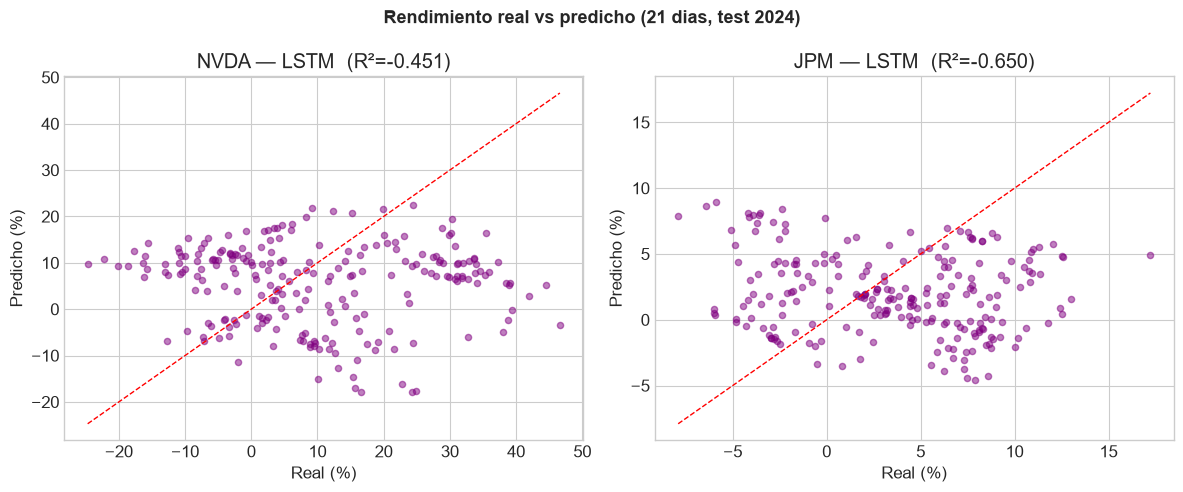

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, ticker in zip(axes, ['NVDA', 'JPM']):
    y_te   = seq_data[ticker]['y_test']
    p_lstm = lstm_models[ticker].predict(
        seq_data[ticker]['X_test'], verbose=0
    ).flatten()

    ax.scatter(y_te * 100, p_lstm * 100, alpha=0.5, s=20, c='purple')
    lims = [min(y_te.min(), p_lstm.min()) * 100,
            max(y_te.max(), p_lstm.max()) * 100]
    ax.plot(lims, lims, 'r--', lw=1)
    ax.set_xlabel('Real (%)')
    ax.set_ylabel('Predicho (%)')
    ax.set_title(f'{ticker} — LSTM  (R\u00b2={r2_score(y_te, p_lstm):.3f})')

plt.suptitle('Rendimiento real vs predicho (21 dias, test 2024)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 8. De predicciones a portafolio

Mismo flujo que la Parte 2: promedio las predicciones del test set, anualizo, y meto los rendimientos esperados al optimizador de Markowitz. Comparo el portafolio LSTM contra el histórico.

In [17]:
pred_ret_lstm = {}

for ticker in TICKERS:
    p = lstm_models[ticker].predict(
        seq_data[ticker]['X_test'], verbose=0
    ).flatten()
    pred_ret_lstm[ticker] = p.mean() * (TRADING_DAYS / HORIZON)

er_lstm = np.array([pred_ret_lstm[tk] for tk in TICKERS])

# Historico (solo training set)
train_daily = prices[TICKERS].loc[:SPLIT_DATE].pct_change().dropna()
er_hist = (train_daily.mean() * TRADING_DAYS).values
cov_mat = (train_daily.cov() * TRADING_DAYS).values

comp = pd.DataFrame({
    'Historico (%)': er_hist * 100,
    'LSTM (%)':      er_lstm * 100,
}, index=TICKERS).round(2)

print("Rendimientos esperados anualizados:")
print(comp.to_string())

Rendimientos esperados anualizados:
      Historico (%)   LSTM (%)
AAPL          29.90  29.559999
MSFT          27.58  67.089996
JPM           13.62  24.010000
JNJ            6.60   4.100000
XOM           20.79  23.250000
KO             7.38   9.210000
AMZN          18.90   6.460000
NVDA          67.65  65.820000
CAT           25.06  31.540001
PG             9.24   1.930000


Si las predicciones LSTM difieren de las de RF/XGB (Parte 2), puede ser porque la red captó patrones temporales distintos o porque la arquitectura y el entrenamiento llevan a generalizaciones diferentes. Esa diversidad entre modelos es justamente lo que se compara en la Parte 4.

## 9. Optimización

Mismo optimizador que las partes anteriores. Solo cambia el vector de rendimientos esperados.

In [18]:
def portfolio_performance(w, er, cov):
    ret = np.dot(w, er)
    vol = np.sqrt(w @ cov @ w)
    sharpe = (ret - RISK_FREE_RATE) / vol
    return ret, vol, sharpe

def neg_sharpe(w, er, cov):
    return -(np.dot(w, er) - RISK_FREE_RATE) / np.sqrt(w @ cov @ w)

n = len(TICKERS)
x0   = np.ones(n) / n
cons = {'type': 'eq', 'fun': lambda w: w.sum() - 1}
bnds = tuple((0, 1) for _ in range(n))

opt = {}
for label, er in [('Historico', er_hist), ('LSTM', er_lstm)]:
    res = minimize(neg_sharpe, x0, args=(er, cov_mat),
                   method='SLSQP', bounds=bnds, constraints=cons)
    w = res.x
    r, v, s = portfolio_performance(w, er, cov_mat)
    opt[label] = {'w': w, 'ret': r, 'vol': v, 'sharpe': s}

    print(f"--- {label} ---")
    print(f"  Rendimiento esperado: {r*100:.2f}%")
    print(f"  Volatilidad:          {v*100:.2f}%")
    print(f"  Sharpe:               {s:.4f}")
    nz = w > 0.001
    for tk, wt in zip(np.array(TICKERS)[nz], w[nz]):
        print(f"    {tk:6s}: {wt*100:.1f}%")
    print()

--- Historico ---
  Rendimiento esperado: 55.92%
  Volatilidad:          43.31%
  Sharpe:               1.1759
    XOM   : 7.5%
    NVDA  : 73.2%
    CAT   : 19.3%

--- LSTM ---
  Rendimiento esperado: 64.95%
  Volatilidad:          31.44%
  Sharpe:               1.9071
    MSFT  : 94.0%
    CAT   : 6.0%



## 10. Comparación de asignaciones

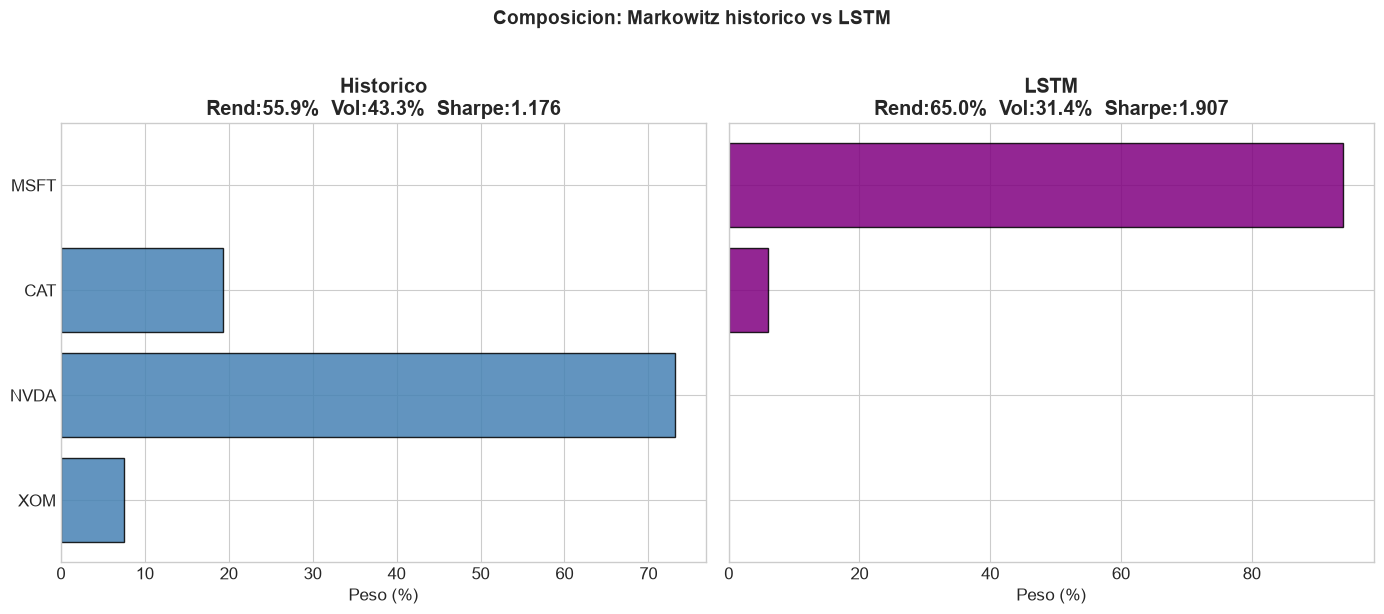

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

colors_map = {'Historico': 'steelblue', 'LSTM': 'purple'}

for ax, label in zip(axes, ['Historico', 'LSTM']):
    w = opt[label]['w']
    mask = w > 0.001
    ax.barh(np.array(TICKERS)[mask], w[mask] * 100,
            color=colors_map[label], edgecolor='black', alpha=0.85)
    ax.set_xlabel('Peso (%)')
    r, v, s = opt[label]['ret'], opt[label]['vol'], opt[label]['sharpe']
    ax.set_title(f'{label}\nRend:{r*100:.1f}%  Vol:{v*100:.1f}%  Sharpe:{s:.3f}',
                 fontweight='bold')

plt.suptitle('Composicion: Markowitz historico vs LSTM',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 11. Backtest en 2024

Pesos fijos durante todo el año, igual que en las partes anteriores. El backtesting formal con rebalanceo se hace en la Parte 4.

In [20]:
test_prices = prices[prices.index >= SPLIT_DATE]
test_daily  = test_prices[TICKERS].pct_change().dropna()
test_bench  = test_prices[BENCHMARK].pct_change().dropna()

common = test_daily.index.intersection(test_bench.index)
test_daily = test_daily.loc[common]
test_bench = test_bench.loc[common]

cum = {}
for label in ['Historico', 'LSTM']:
    cum[label] = (1 + test_daily @ opt[label]['w']).cumprod()
cum['Equal-Weight'] = (1 + test_daily.mean(axis=1)).cumprod()
cum['SPY']          = (1 + test_bench).cumprod()

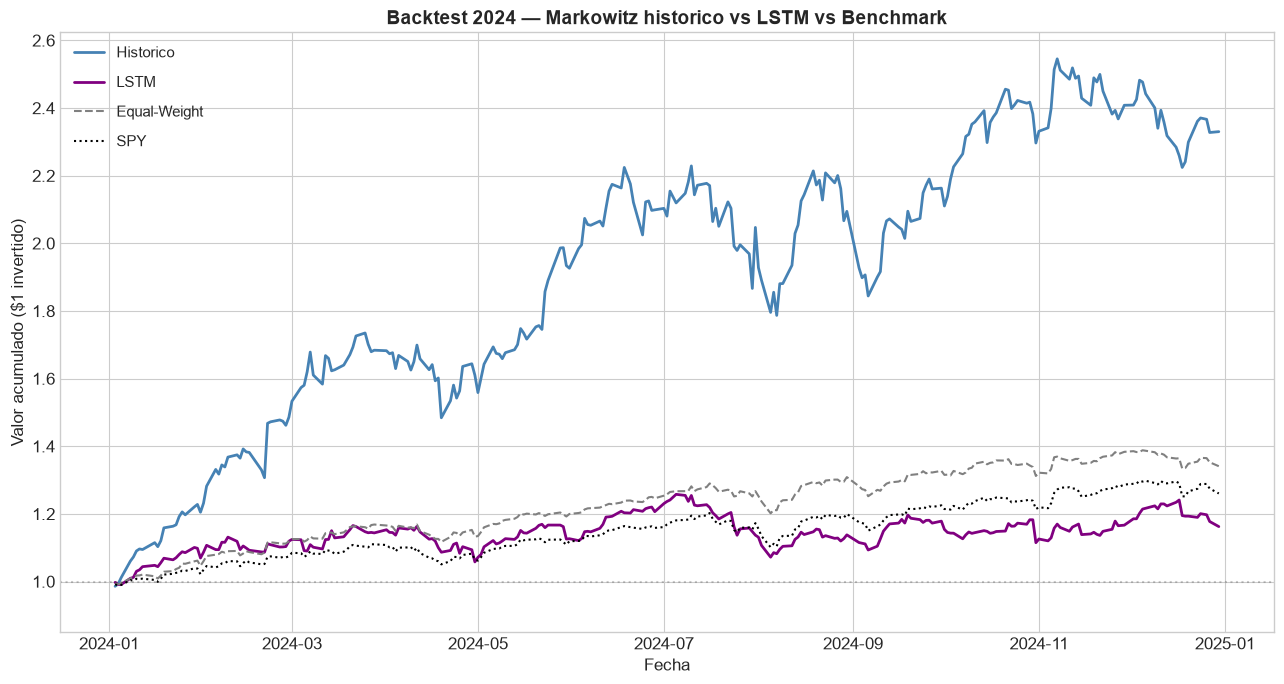

In [21]:
fig, ax = plt.subplots(figsize=(13, 7))

styles = {
    'Historico':    ('steelblue',  '-',  2.0),
    'LSTM':         ('purple',     '-',  2.0),
    'Equal-Weight': ('gray',       '--', 1.5),
    'SPY':          ('black',      ':',  1.5),
}

for label, (c, ls, lw) in styles.items():
    ax.plot(cum[label].index, cum[label].values, color=c, ls=ls, lw=lw, label=label)

ax.axhline(y=1, color='black', ls=':', alpha=0.2)
ax.set_xlabel('Fecha')
ax.set_ylabel('Valor acumulado ($1 invertido)')
ax.set_title('Backtest 2024 — Markowitz historico vs LSTM vs Benchmark',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=11, labelspacing=1.0)
ax.set_ylim(bottom=0.85)
plt.tight_layout()
plt.show()

In [22]:
print("Resultados 2024 (out-of-sample)")
print("=" * 58)
print(f"{'Portafolio':>14s}  {'Retorno':>9s}  {'Vol':>7s}  {'Sharpe':>7s}")
print("-" * 58)

for label in ['Historico', 'LSTM', 'Equal-Weight', 'SPY']:
    if label == 'SPY':
        dr = test_bench
    elif label == 'Equal-Weight':
        dr = test_daily.mean(axis=1)
    else:
        dr = test_daily @ opt[label]['w']

    ann_ret = dr.mean() * TRADING_DAYS
    ann_vol = dr.std()  * np.sqrt(TRADING_DAYS)
    sharpe  = (ann_ret - RISK_FREE_RATE) / ann_vol
    total   = cum[label].iloc[-1] - 1

    print(f"{label:>14s}  {total*100:>+8.2f}%  {ann_vol*100:>6.1f}%  {sharpe:>7.3f}")

Resultados 2024 (out-of-sample)
    Portafolio    Retorno      Vol   Sharpe
----------------------------------------------------------
     Historico   +133.03%    40.0%    2.207
          LSTM    +16.26%    19.3%    0.624
  Equal-Weight    +34.10%    11.7%    2.166
           SPY    +26.05%    12.6%    1.520


## 12. Resumen

In [23]:
resumen = pd.DataFrame({
    'Rend. Esperado (%)': [opt[l]['ret']*100 for l in ['Historico','LSTM']],
    'Volatilidad (%)':    [opt[l]['vol']*100 for l in ['Historico','LSTM']],
    'Sharpe (esperado)':  [opt[l]['sharpe']  for l in ['Historico','LSTM']],
}, index=['Markowitz Hist.', 'LSTM'])

resumen.round(4)

,Rend. Esperado (%),Volatilidad (%),Sharpe (esperado)
Markowitz Hist.,55.9248,43.3073,1.1759
LSTM,64.9527,31.4365,1.9071


### Conclusiones

La LSTM aporta una dimensión que los modelos de la Parte 2 no tienen: contexto temporal.

1. **Secuencias vs puntos** — En vez de ver un snapshot de indicadores, la LSTM ve cómo evolucionaron durante 60 días. Puede aprender patrones como "RSI subiendo sostenidamente seguido de una caída de momentum" que RF/XGB no capturan directamente.

2. **Complejidad vs datos** — Con ~29,000 parámetros y ~900 secuencias de entrenamiento por acción, estamos en el límite de lo que deep learning puede extraer. Más capas o más unidades probablemente empeorarían los resultados por overfitting. El early stopping y dropout son fundamentales.

3. **Diversidad de modelos** — Cada método (Markowitz puro, RF, XGB, LSTM) tiene sesgos diferentes. Uno puede captar señales que los otros pierden. En la Parte 4 se evalúa si esa diversidad se traduce en mejor desempeño combinado.

4. **Limitaciones** — Las LSTM tardan más en entrenar y no dan feature importance directa (son más "caja negra" que RF/XGB). Además, los resultados pueden variar ligeramente entre ejecuciones por la inicialización aleatoria de los pesos, aunque el seed ayuda a reproducirlos. Los features siguen siendo puramente técnicos.

En la Parte 4 junto las cuatro estrategias y hago backtesting formal: rebalanceo mensual, drawdown máximo, turnover y costos de transacción. Ahí se ve cuál combinación realmente funciona mejor.